# Explainable ML for Normal vs Abnormal ECG Classification (PTB-XL)
**Pipeline:** metadata → binary label → official-fold split → download only the sampled records → feature extraction (lead II) → 3 models → evaluation → SHAP → save model → Streamlit prototype.

**How to use:** `Runtime > Run all` works, but run the cells one at a time the first time and read the printed output.
CPU runtime is enough (no GPU needed). Everything you want to keep is saved to Google Drive in `MyDrive/ptbxl_project`.

## 1. Setup

In [1]:
!pip -q install wfdb shap xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 5.7 MB/s eta 0:00:00


In [2]:
import os, sys, glob, ast, json, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount("/content/drive")

WORK = "/content/drive/MyDrive/ptbxl_project"          # everything you want to keep lives here
for d in ["", "figures", "models", "data"]:
    os.makedirs(f"{WORK}/{d}", exist_ok=True)
os.chdir(WORK); sys.path.insert(0, WORK)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- configuration: edit these ----------------
N_TRAIN, N_VAL, N_TEST = 7000, 1500, 1500  # 10,000 records sampled from folds 1-8 / 9 / 10 (None = use all)
LEADS = ["II"]                             # e.g. ["II", "V1", "V5"] to engineer features from several leads
USE_DEMOGRAPHICS = False                   # age/sex: only switch on if you document it (see report notes)

Mounted at /content/drive


### Feature-extraction module
This cell writes `ecg_features.py` into your Drive folder. The notebook **and** the Streamlit app both import it,
so the prototype uses exactly the same preprocessing as training.
Signal processing: 0.5-40 Hz band-pass (removes baseline wander + noise), signals kept in mV, features computed per record.

In [3]:
%%writefile ecg_features.py
"""ECG feature extraction for the PTB-XL normal-vs-abnormal project.

One function turns a (samples x leads) ECG array into a flat dict of features.
The same code is used for training (notebook) and for inference (Streamlit app),
so the prototype can never drift away from the training pipeline.
"""
import numpy as np
from scipy import signal, stats

FS = 100                      # all signals are processed at 100 Hz
BANDS = {                     # frequency bands (Hz) for Welch band power
    "baseline": (0.5, 5),     # P/T waves, slow components
    "qrs": (5, 15),           # QRS complex
    "high": (15, 40),         # fast components / noise
}


def bandpass(x, fs=FS, low=0.5, high=40.0, order=3):
    """Zero-phase band-pass filter: removes baseline wander and high-frequency noise."""
    sos = signal.butter(order, [low, high], btype="band", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, x)


def statistical_features(x, prefix):
    """Time-domain statistics. x stays in mV so amplitude keeps its clinical meaning."""
    return {
        f"{prefix}_mean": float(np.mean(x)),
        f"{prefix}_std": float(np.std(x)),
        f"{prefix}_min": float(np.min(x)),
        f"{prefix}_max": float(np.max(x)),
        f"{prefix}_range": float(np.ptp(x)),
        f"{prefix}_rms": float(np.sqrt(np.mean(x ** 2))),
        f"{prefix}_energy": float(np.sum(x ** 2) / len(x)),
        f"{prefix}_skew": float(stats.skew(x)),
        f"{prefix}_kurtosis": float(stats.kurtosis(x)),
    }


def frequency_features(x, prefix, fs=FS):
    """Welch power spectral density -> band powers, dominant frequency, centroid, entropy."""
    freqs, psd = signal.welch(x, fs=fs, nperseg=min(256, len(x)))
    total = psd.sum() + 1e-12
    feats = {}
    for name, (lo, hi) in BANDS.items():
        mask = (freqs >= lo) & (freqs < hi)
        feats[f"{prefix}_bp_{name}"] = float(psd[mask].sum() / total)   # relative band power
    p = psd / total
    feats[f"{prefix}_dom_freq"] = float(freqs[np.argmax(psd)])
    feats[f"{prefix}_spec_centroid"] = float(np.sum(freqs * p))
    feats[f"{prefix}_spec_entropy"] = float(-np.sum(p * np.log2(p + 1e-12)))
    return feats


def beat_features(x, prefix, fs=FS):
    """R-peak based features: heart rate and heart-rate variability. NaN if not reliable."""
    names = ["n_beats", "hr_mean", "rr_mean", "rr_std", "rmssd", "pnn50", "rr_cv",
             "r_amp_mean", "r_amp_std"]
    nan = {f"{prefix}_{n}": np.nan for n in names}
    # R peaks are usually positive; if the negative deflection dominates, flip the polarity
    xp = x if abs(x.max()) >= abs(x.min()) else -x
    if xp.max() <= 0:
        return nan
    peaks, _ = signal.find_peaks(xp, distance=int(0.25 * fs), height=0.5 * xp.max())
    if len(peaks) < 3:
        return nan
    rr = np.diff(peaks) / fs                       # seconds between beats
    drr = np.diff(rr)
    amps = xp[peaks]
    return {
        f"{prefix}_n_beats": float(len(peaks)),
        f"{prefix}_hr_mean": float(60.0 / rr.mean()),
        f"{prefix}_rr_mean": float(rr.mean()),
        f"{prefix}_rr_std": float(rr.std()),                              # SDNN
        f"{prefix}_rmssd": float(np.sqrt(np.mean(drr ** 2))) if len(drr) else np.nan,
        f"{prefix}_pnn50": float(np.mean(np.abs(drr) > 0.05)) if len(drr) else np.nan,
        f"{prefix}_rr_cv": float(rr.std() / rr.mean()),
        f"{prefix}_r_amp_mean": float(amps.mean()),
        f"{prefix}_r_amp_std": float(amps.std()),
    }


def extract_features(sig, sig_names, fs, leads=("II",), full_set_leads=("II",)):
    """sig: (n_samples, n_leads) array in mV. Returns a dict of features.

    leads          -> leads that get basic statistical + frequency features
    full_set_leads -> leads that additionally get R-peak / HRV features
    """
    sig = np.asarray(sig, dtype=float)
    if fs != FS:                                   # e.g. 500 Hz records -> 100 Hz
        n_new = int(round(sig.shape[0] * FS / fs))
        sig = signal.resample(sig, n_new, axis=0)
    feats = {}
    for lead in leads:
        if lead not in sig_names:
            raise ValueError(f"Lead {lead} not found in {sig_names}")
        x = bandpass(np.nan_to_num(sig[:, sig_names.index(lead)]))
        feats.update(statistical_features(x, lead))
        feats.update(frequency_features(x, lead))
        if lead in full_set_leads:
            feats.update(beat_features(x, lead))
    return feats

Overwriting ecg_features.py


## 2. Metadata (no big download)
We do **not** download the 1.8 GB zip. This cell uses the two small CSV files you already have in `/content`
(`ptbxl_database.csv`, `scp_statements.csv`); any file that is missing is fetched from PhysioNet (they are only a few MB).
The waveform files for the sampled records are downloaded later, in section 5.

In [4]:
import shutil, requests
BASE = "https://physionet.org/files/ptb-xl/1.0.3"
DATA = "/content/ptbxl_subset"                      # local (fast) folder for metadata + the records we download
os.makedirs(DATA, exist_ok=True)
for fn in ["ptbxl_database.csv", "scp_statements.csv"]:
    dst = f"{DATA}/{fn}"
    if os.path.exists(dst):
        continue
    if os.path.exists(f"/content/{fn}"):
        shutil.copy(f"/content/{fn}", dst); print("copied from /content:", fn)
    else:
        r = requests.get(f"{BASE}/{fn}", timeout=60); r.raise_for_status()
        open(dst, "wb").write(r.content); print("downloaded:", fn)
print("Metadata folder:", DATA)

copied from /content: ptbxl_database.csv
copied from /content: scp_statements.csv
Metadata folder: /content/ptbxl_subset


## 3. Read metadata and define the binary target
* Each record has SCP statements (`scp_codes`). Only **diagnostic** statements are mapped to the 5 superclasses: NORM, MI, STTC, CD, HYP.
* **Normal (0)** = diagnostic superclasses are exactly `["NORM"]`. **Abnormal (1)** = any other diagnostic superclass.
* Records with no diagnostic statement (e.g. rhythm-only) are dropped - state this in your report.

In [5]:
Y = pd.read_csv(f"{DATA}/ptbxl_database.csv", index_col="ecg_id")
Y["scp_codes"] = Y["scp_codes"].apply(ast.literal_eval)
scp = pd.read_csv(f"{DATA}/scp_statements.csv", index_col=0)
scp = scp[scp["diagnostic"] == 1]                              # diagnostic statements only
print("All records:", Y.shape[0], "| patients:", Y.patient_id.nunique())

def to_superclasses(codes):
    return sorted({scp.loc[c, "diagnostic_class"] for c in codes if c in scp.index})

Y["superclasses"] = Y["scp_codes"].apply(to_superclasses)
Y = Y[Y["superclasses"].str.len() > 0].copy()                  # drop records without a diagnostic label
Y["abnormal"] = Y["superclasses"].apply(lambda s: int(s != ["NORM"]))
print("Labelled records:", Y.shape[0])
print(Y["abnormal"].value_counts().rename({0: "normal", 1: "abnormal"}))

All records: 21837 | patients: 18885
Labelled records: 21430
abnormal
abnormal    12347
normal       9083
Name: count, dtype: int64


## 4. Official-fold split + leakage checks
PTB-XL's `strat_fold` column (1-10) was built so that **all records of one patient are in the same fold**.
Recommended protocol: folds 1-8 = train, fold 9 = validation, fold 10 = test (about 80/10/10).
We then take a fixed random subset of each part to keep it light. Sampling records *inside* a fold cannot split a patient across folds.

In [6]:
def take(df, n):
    return df if (n is None or n >= len(df)) else df.sample(n=n, random_state=SEED)

meta = pd.concat([
    take(Y[Y.strat_fold <= 8], N_TRAIN).assign(split="train"),
    take(Y[Y.strat_fold == 9], N_VAL).assign(split="val"),
    take(Y[Y.strat_fold == 10], N_TEST).assign(split="test"),
])

# ---- leakage checks (screenshot this output for the report) ----
pid = {s: set(meta.loc[meta.split == s, "patient_id"]) for s in ["train", "val", "test"]}
assert not (pid["train"] & pid["val"]), "patient overlap: train/val"
assert not (pid["train"] & pid["test"]), "patient overlap: train/test"
assert not (pid["val"] & pid["test"]), "patient overlap: val/test"
assert meta.index.is_unique, "duplicate ecg_id"
print("No patient appears in more than one split.")
print(meta.groupby("split")["abnormal"].agg(records="count", abnormal_rate="mean").round(3))

No patient appears in more than one split.
       records  abnormal_rate
split                        
test      1500          0.590
train     7000          0.582
val       1500          0.567


## 5a. Download only the selected records
Only the 100 Hz files (`.hea` + `.dat`, about 25 KB each) of the ~10,000 sampled records are fetched, with 16 parallel threads
(typically a few minutes, about 240 MB). Already-downloaded files are skipped, so re-running is safe. If the features CSV is cached in Drive, nothing is downloaded.

In [7]:
import time
from concurrent.futures import ThreadPoolExecutor

FEATURE_CSV = f"{WORK}/data/features_{'-'.join(LEADS)}_{N_TRAIN}_{N_VAL}_{N_TEST}.csv"
session = requests.Session()

def fetch(rel):
    """Download <rel>.hea and <rel>.dat (rel like records100/00000/00001_lr). Returns (rel, error or None)."""
    for ext in (".hea", ".dat"):
        dst = f"{DATA}/{rel}{ext}"
        if os.path.exists(dst) and os.path.getsize(dst) > 0:
            continue
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        for attempt in range(4):
            try:
                r = session.get(f"{BASE}/{rel}{ext}", timeout=30); r.raise_for_status()
                with open(dst, "wb") as fh:
                    fh.write(r.content)
                break
            except Exception as e:
                if attempt == 3:
                    return rel, str(e)
                time.sleep(1 + attempt)
    return rel, None

if os.path.exists(FEATURE_CSV):
    print("Cached features found in Drive - skipping the record download.")
else:
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=16) as ex:
        out = list(tqdm(ex.map(fetch, meta["filename_lr"]), total=len(meta)))
    failed = [r for r, e in out if e]
    print(f"Downloaded {len(out) - len(failed)} / {len(out)} records in {time.time() - t0:.0f}s; failed: {len(failed)}")

  0%|          | 0/10000 [00:00<?, ?it/s]

Downloaded 9973 / 10000 records in 1220s; failed: 27


## 5b. Feature extraction (one row per record)
Uses the 100 Hz files (`filename_lr`). Unreadable records are logged and skipped. The result is cached in Drive,
so re-running after a runtime reset takes seconds instead of minutes.

In [8]:
import wfdb
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from ecg_features import extract_features

def process(ecg_id, filename_lr):
    try:
        sig, fields = wfdb.rdsamp(f"{DATA}/{filename_lr}")
        f = extract_features(sig, fields["sig_name"], fields["fs"], leads=LEADS, full_set_leads=("II",))
        f["ecg_id"] = ecg_id
        return f
    except Exception as e:                                     # corrupt / unreadable record
        return {"ecg_id": ecg_id, "_error": str(e)}

if os.path.exists(FEATURE_CSV):
    feats = pd.read_csv(FEATURE_CSV, index_col="ecg_id")
    print("Loaded cached features:", feats.shape)
else:
    rows = Parallel(n_jobs=-1)(delayed(process)(i, fn)
                               for i, fn in tqdm(zip(meta.index, meta.filename_lr), total=len(meta)))
    feats = pd.DataFrame(rows).set_index("ecg_id")
    if "_error" in feats.columns:
        print("Unreadable records skipped:", int(feats["_error"].notna().sum()))
        feats = feats[feats["_error"].isna()].drop(columns="_error")
    feats.to_csv(FEATURE_CSV)
    print("Saved:", FEATURE_CSV, feats.shape)

data = feats.join(meta[["patient_id", "split", "abnormal", "superclasses"]], how="inner")
if USE_DEMOGRAPHICS:
    data["age"] = meta["age"].clip(upper=90)                   # PTB-XL codes ages >89 as 300
    data["sex"] = meta["sex"]

# Features = numeric columns only. IDs, split, label and diagnostic text must never be inputs.
NOT_FEATURES = {"patient_id", "split", "abnormal", "superclasses"}
FEATURES = [c for c in data.columns if c not in NOT_FEATURES]
assert not ({"scp_codes", "report", "strat_fold", "patient_id", "abnormal"} & set(FEATURES))
print(len(FEATURES), "features:", FEATURES[:6], "...")

tr, va, te = (data[data.split == s] for s in ["train", "val", "test"])
X_tr, y_tr = tr[FEATURES], tr["abnormal"]
X_va, y_va = va[FEATURES], va["abnormal"]
X_te, y_te = te[FEATURES], te["abnormal"]
X_trva, y_trva = pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va])
print("train/val/test:", len(tr), len(va), len(te))

  0%|          | 0/10000 [00:00<?, ?it/s]

Unreadable records skipped: 27
Saved: /content/drive/MyDrive/ptbxl_project/data/features_II_7000_1500_1500.csv (9973, 24)
24 features: ['II_mean', 'II_std', 'II_min', 'II_max', 'II_range', 'II_rms'] ...
train/val/test: 6984 1493 1496


## 6. Exploratory data analysis
Class balance, diagnostic superclasses, **before/after preprocessing**, feature distributions by class, correlations.
All figures are saved to `figures/` at 200 dpi for the report.

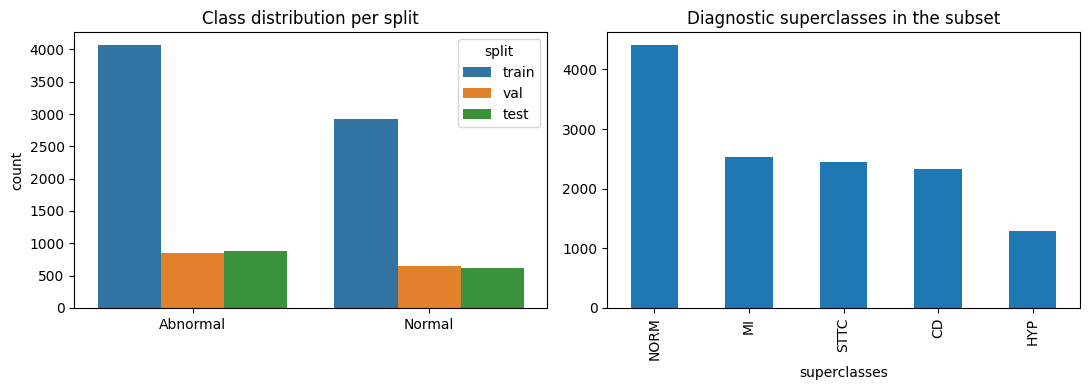

Missing values in train (fraction):
II_hr_mean    0.039
II_rr_mean    0.039
II_rr_std     0.039
II_rmssd      0.039
II_pnn50      0.039
dtype: float64


,count,mean,std,min,25%,50%,75%,max
II_mean,6984.0,-0.000,0.004,-0.056,-0.001,0.000,0.002,0.024
II_std,6984.0,0.134,0.057,0.024,0.095,0.123,0.160,0.736
II_min,6984.0,-0.345,0.257,-2.693,-0.415,-0.263,-0.180,-0.055
II_max,6984.0,0.736,0.388,0.080,0.454,0.681,0.951,3.154
II_range,6984.0,1.081,0.490,0.180,0.754,0.984,1.288,5.847
II_rms,6984.0,0.134,0.057,0.024,0.095,0.123,0.160,0.738
II_energy,6984.0,0.021,0.022,0.001,0.009,0.015,0.026,0.544
II_skew,6984.0,2.118,1.989,-5.114,1.006,2.563,3.602,6.398
II_kurtosis,6984.0,12.247,7.716,-0.702,6.110,11.262,17.278,61.290
II_bp_baseline,6984.0,0.369,0.150,0.017,0.259,0.346,0.459,0.922


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x=data["abnormal"].map({0: "Normal", 1: "Abnormal"}), hue=data["split"], ax=ax[0])
ax[0].set_title("Class distribution per split"); ax[0].set_xlabel("")
data["superclasses"].explode().value_counts().plot.bar(ax=ax[1], title="Diagnostic superclasses in the subset")
plt.tight_layout(); plt.savefig(f"{WORK}/figures/eda_classes.png", dpi=200); plt.show()

print("Missing values in train (fraction):")
print(tr[FEATURES].isna().mean().sort_values(ascending=False).head(5).round(3))
display(tr[FEATURES].describe().T.round(3))

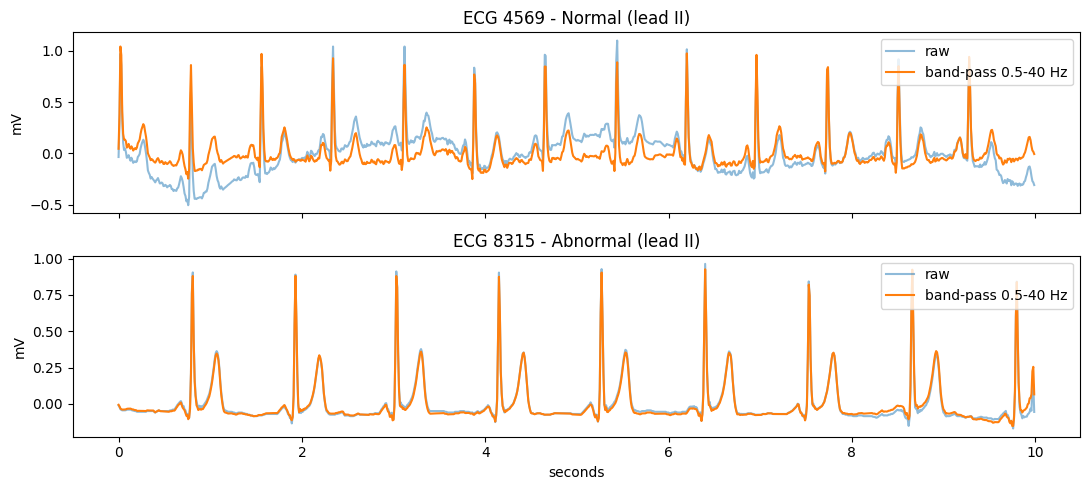

In [10]:
# Before / after preprocessing (raw lead II vs 0.5-40 Hz band-pass)
from ecg_features import bandpass
ids = [meta[meta.abnormal == 0].index[0], meta[meta.abnormal == 1].index[0]]
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for a, i in zip(ax, ids):
    fetch(meta.loc[i, "filename_lr"])                          # no-op if already downloaded
    sig, fld = wfdb.rdsamp(f"{DATA}/{meta.loc[i, 'filename_lr']}")
    raw = np.nan_to_num(sig[:, fld["sig_name"].index("II")])
    t = np.arange(len(raw)) / fld["fs"]
    a.plot(t, raw, alpha=0.5, label="raw"); a.plot(t, bandpass(raw), label="band-pass 0.5-40 Hz")
    a.set_title(f"ECG {i} - {'Abnormal' if meta.loc[i, 'abnormal'] else 'Normal'} (lead II)"); a.set_ylabel("mV")
    a.legend(loc="upper right")
ax[-1].set_xlabel("seconds")
plt.tight_layout(); plt.savefig(f"{WORK}/figures/eda_before_after_filter.png", dpi=200); plt.show()

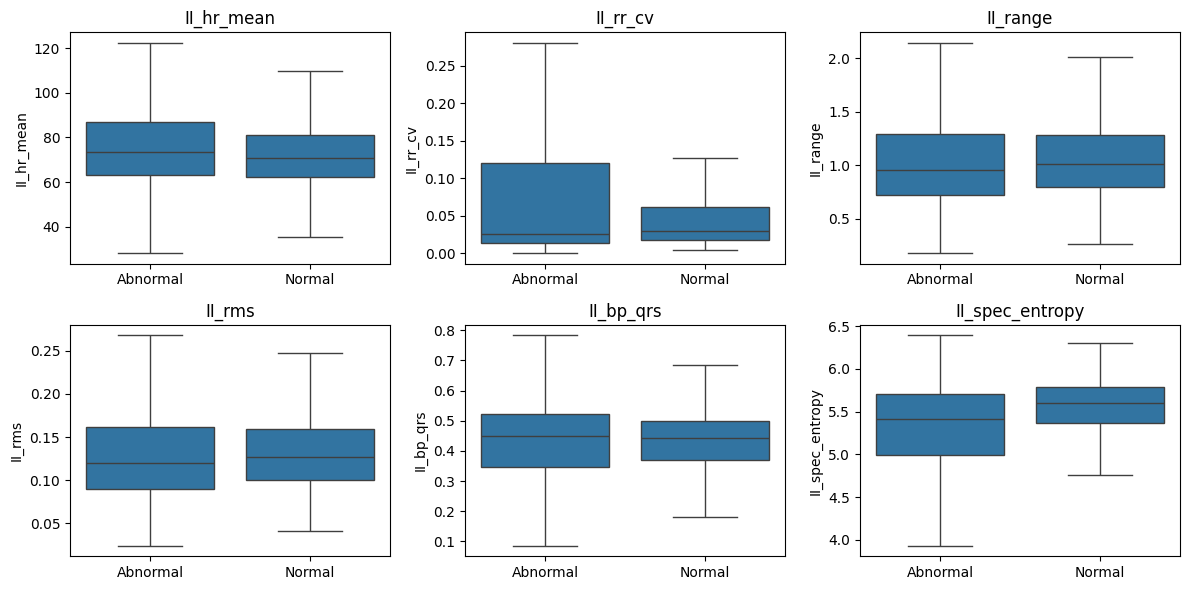

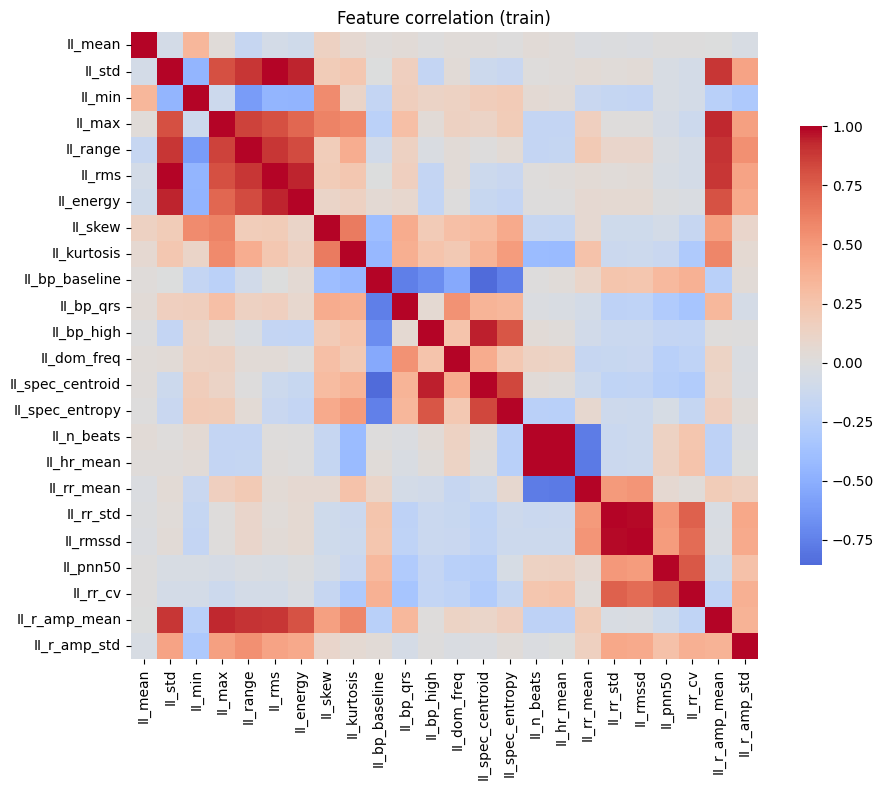

In [11]:
show = [f for f in ["II_hr_mean", "II_rr_cv", "II_range", "II_rms", "II_bp_qrs", "II_spec_entropy"] if f in FEATURES]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for a, f in zip(axes.ravel(), show):
    sns.boxplot(x=tr["abnormal"].map({0: "Normal", 1: "Abnormal"}), y=tr[f], ax=a, showfliers=False)
    a.set_xlabel(""); a.set_title(f)
plt.tight_layout(); plt.savefig(f"{WORK}/figures/eda_feature_boxplots.png", dpi=200); plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(tr[FEATURES].corr(), cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Feature correlation (train)"); plt.tight_layout()
plt.savefig(f"{WORK}/figures/eda_correlation.png", dpi=200); plt.show()

## 7. Train and tune three models
* Same split for all models. Hyper-parameters are chosen on the **validation fold (9)** with `PredefinedSplit`, then the best model is refit on train+val.
* Imbalance: `class_weight="balanced"` (LR, RF) and `scale_pos_weight` (XGBoost).
* Missing features (e.g. unreliable R-peaks) are median-imputed **inside the pipeline**, fitted on training data only. XGBoost handles NaN natively.
* Logistic Regression needs scaling (`StandardScaler`); tree models don't.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit, StratifiedGroupKFold, cross_val_score
from xgboost import XGBClassifier

pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

models = {
    "Logistic Regression": (
        Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=3000))]),
        {"clf__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (
        Pipeline([("imp", SimpleImputer(strategy="median")),
                  ("clf", RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED))]),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 12], "clf__min_samples_leaf": [1, 5]}),
    "XGBoost": (
        XGBClassifier(scale_pos_weight=pos_weight, eval_metric="logloss", tree_method="hist",
                      n_jobs=-1, random_state=SEED),
        {"n_estimators": [200, 400], "max_depth": [3, 5], "learning_rate": [0.05, 0.1]}),
}

# -1 = always in training part, 0 = validation fold
ps = PredefinedSplit(np.r_[np.full(len(X_tr), -1), np.zeros(len(X_va), dtype=int)])
fitted, val_auc, best_params = {}, {}, {}
for name, (est, grid) in models.items():
    gs = GridSearchCV(est, grid, scoring="roc_auc", cv=ps, refit=True)
    gs.fit(X_trva, y_trva)
    fitted[name], val_auc[name], best_params[name] = gs.best_estimator_, gs.best_score_, gs.best_params_
    print(f"{name:20s} validation AUC = {gs.best_score_:.4f} | {gs.best_params_}")

Logistic Regression  validation AUC = 0.7801 | {'clf__C': 10}
Random Forest        validation AUC = 0.8245 | {'clf__max_depth': 12, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}
XGBoost              validation AUC = 0.8359 | {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400}


In [13]:
# Patient-grouped 5-fold CV on the training part (extra robustness evidence for the report)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, m in fitted.items():
    s = cross_val_score(m, X_tr, y_tr, groups=tr["patient_id"].values, cv=cv, scoring="roc_auc")
    cv_rows.append({"Model": name, "CV ROC-AUC mean": s.mean(), "CV ROC-AUC std": s.std()})
cv_table = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_table.to_csv(f"{WORK}/figures/cv_results.csv"); display(cv_table)

,CV ROC-AUC mean,CV ROC-AUC std
Model,,
Logistic Regression,0.7860,0.0139
Random Forest,0.8230,0.0150
XGBoost,0.8273,0.0170


## 8. Evaluation on the untouched test fold (fold 10)
For a screening-style task, read **recall (sensitivity)**, **specificity**, **F1** and **ROC-AUC** together - accuracy alone can hide missed abnormal ECGs.

In [14]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay)

def auc_ci(y, p, n=1000):
    rng = np.random.default_rng(SEED); y = np.asarray(y); aucs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            aucs.append(roc_auc_score(y[i], p[i]))
    return np.percentile(aucs, [2.5, 97.5])

rows, probs = [], {}
for name, m in fitted.items():
    p = m.predict_proba(X_te)[:, 1]; probs[name] = p
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    lo, hi = auc_ci(y_te, p)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred),
                 "Recall (sensitivity)": recall_score(y_te, pred), "Specificity": tn / (tn + fp),
                 "F1": f1_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, p),
                 "AUC 95% CI": f"{lo:.3f}-{hi:.3f}", "PR-AUC": average_precision_score(y_te, p)})
results = pd.DataFrame(rows).set_index("Model").round(4)
results.to_csv(f"{WORK}/figures/model_comparison.csv"); display(results)

,Accuracy,Precision,Recall (sensitivity),Specificity,F1,ROC-AUC,AUC 95% CI,PR-AUC
Model,,,,,,,,
Logistic Regression,0.6678,0.8051,0.5760,0.7997,0.6715,0.7721,0.750-0.795,0.8366
Random Forest,0.7112,0.8134,0.6621,0.7818,0.7300,0.8076,0.786-0.827,0.8633
XGBoost,0.7239,0.8280,0.6712,0.7997,0.7414,0.8107,0.790-0.830,0.8699


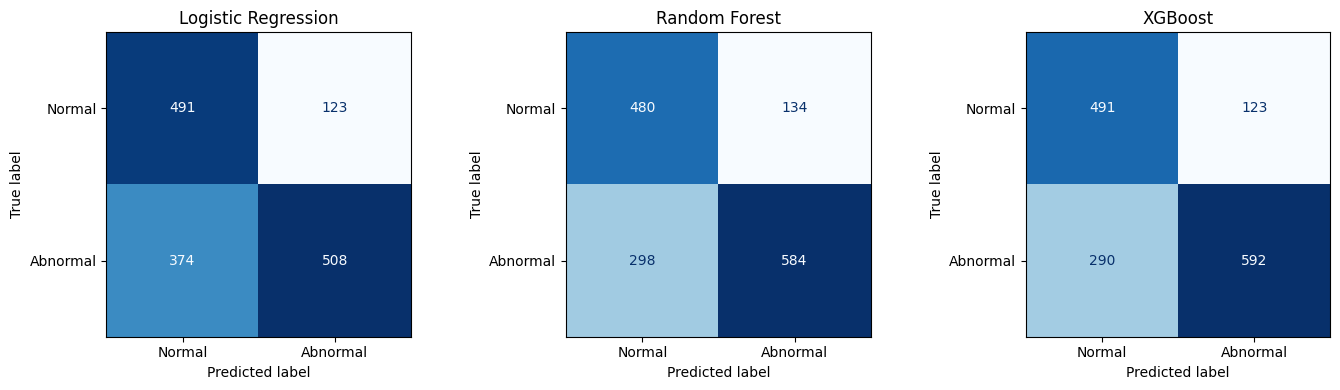

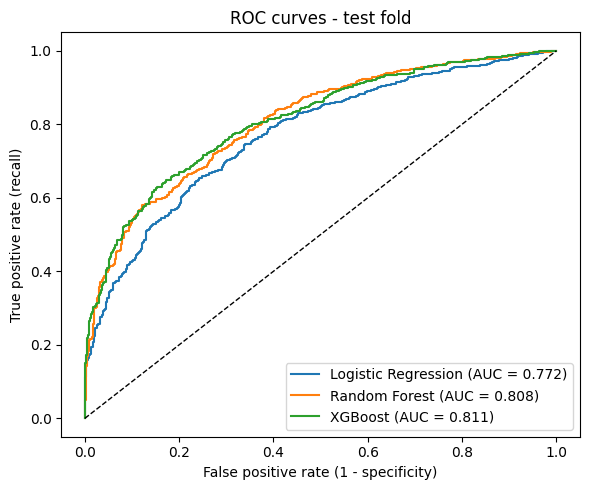

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (name, p) in zip(ax, probs.items()):
    ConfusionMatrixDisplay.from_predictions(y_te, (p >= 0.5).astype(int), display_labels=["Normal", "Abnormal"],
                                            ax=a, colorbar=False, cmap="Blues")
    a.set_title(name)
plt.tight_layout(); plt.savefig(f"{WORK}/figures/confusion_matrices.png", dpi=200); plt.show()

plt.figure(figsize=(6, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_te, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate (1 - specificity)"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves - test fold"); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(f"{WORK}/figures/roc_curves.png", dpi=200); plt.show()

## 9. Error analysis
Which kinds of abnormal ECG does the best model miss, and how do missed cases differ from detected ones?

In [16]:
best_name = max(val_auc, key=val_auc.get)
print("Best model by validation AUC:", best_name)
err = te.assign(prob=probs[best_name]); err["pred"] = (err["prob"] >= 0.5).astype(int)

ab = err[err.abnormal == 1]
per_class = pd.DataFrame({
    "n_test_records": {c: int(ab.superclasses.apply(lambda s, c=c: c in s).sum()) for c in ["MI", "STTC", "CD", "HYP"]},
    "recall": {c: ab[ab.superclasses.apply(lambda s, c=c: c in s)].pred.mean() for c in ["MI", "STTC", "CD", "HYP"]},
}).round(3)
print("Recall per diagnostic superclass (records can carry several):"); display(per_class)

print("False positives:", int(((err.abnormal == 0) & (err.pred == 1)).sum()),
      "| False negatives:", int(((err.abnormal == 1) & (err.pred == 0)).sum()))
cols = [f for f in ["II_hr_mean", "II_rr_cv", "II_range", "II_rms", "II_bp_qrs"] if f in FEATURES]
print("Mean feature values of truly abnormal records, by predicted class (0 = missed, 1 = detected):")
display(ab.groupby("pred")[cols].mean().round(3))

Best model by validation AUC: XGBoost
Recall per diagnostic superclass (records can carry several):


,n_test_records,recall
MI,394,0.731
STTC,372,0.685
CD,353,0.754
HYP,192,0.641


False positives: 123 | False negatives: 290
Mean feature values of truly abnormal records, by predicted class (0 = missed, 1 = detected):


,II_hr_mean,II_rr_cv,II_range,II_rms,II_bp_qrs
pred,,,,,
0,73.984,0.071,1.094,0.133,0.439
1,77.806,0.112,1.068,0.130,0.423


## 10. Explainability
* **SHAP** (TreeExplainer) on the XGBoost model: global beeswarm + bar plot and a local waterfall for one test record.
* **Permutation importance** for all three models (drop in test ROC-AUC when a feature is shuffled) - a model-agnostic cross-check.

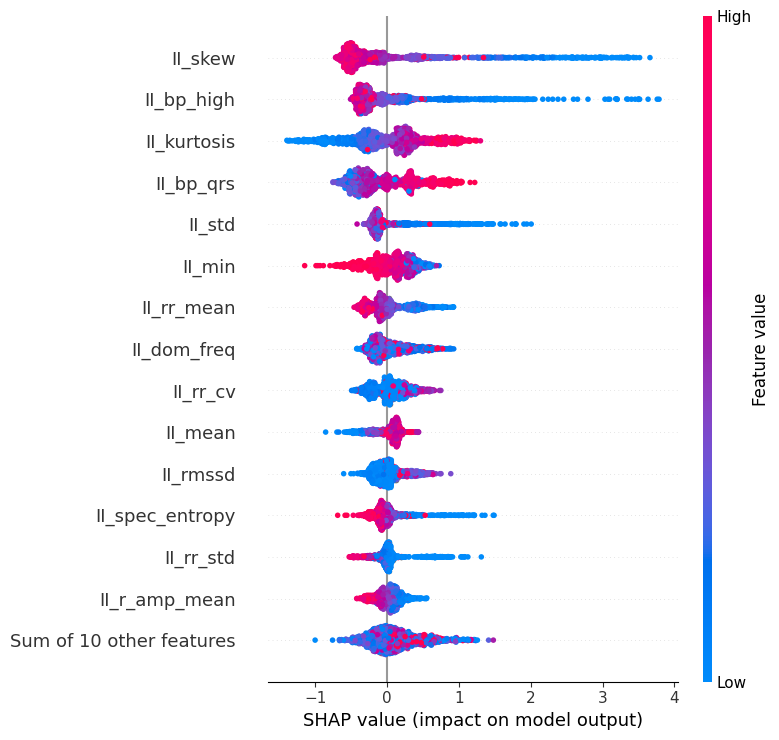

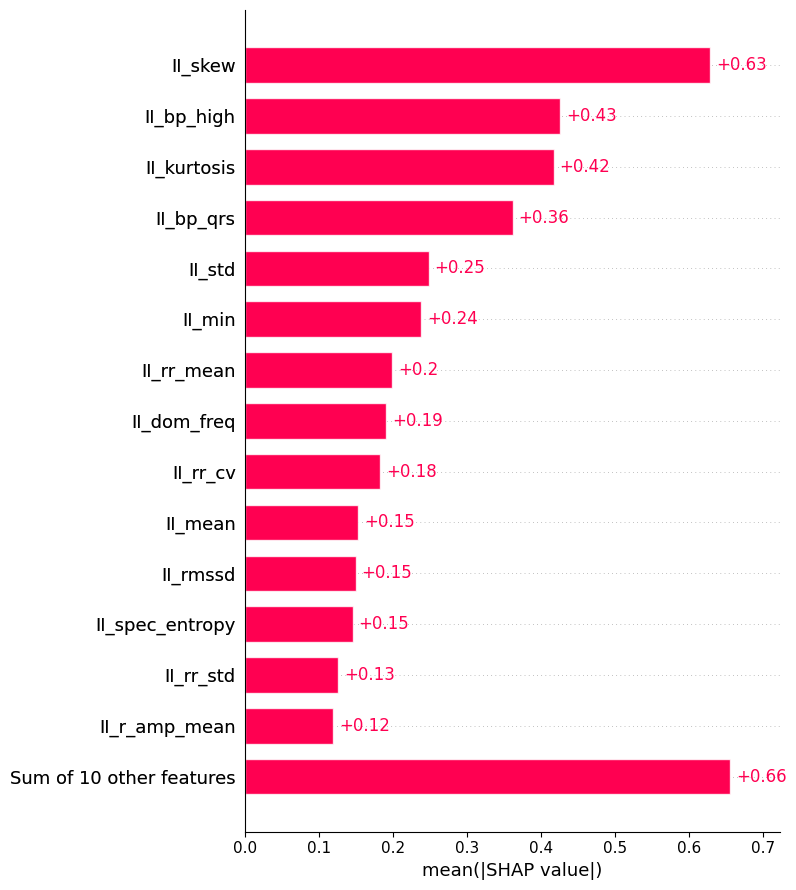

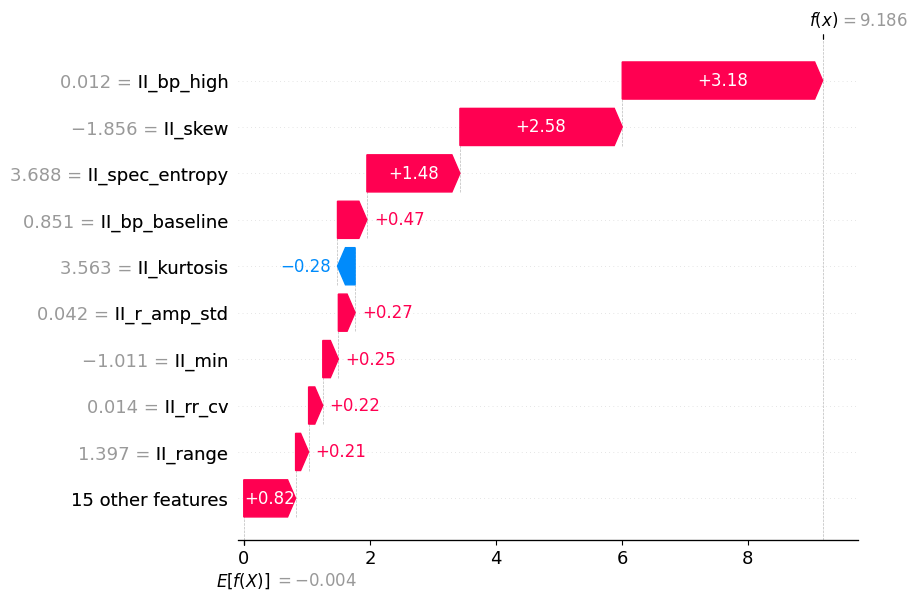

In [17]:
import shap
xgb = fitted["XGBoost"]
explainer = shap.TreeExplainer(xgb)
sv = explainer(X_te)                                   # contributions in log-odds

shap.plots.beeswarm(sv, max_display=15, show=False)
plt.tight_layout(); plt.savefig(f"{WORK}/figures/shap_beeswarm.png", dpi=200, bbox_inches="tight"); plt.show()

shap.plots.bar(sv, max_display=15, show=False)
plt.tight_layout(); plt.savefig(f"{WORK}/figures/shap_bar.png", dpi=200, bbox_inches="tight"); plt.show()

i = int(np.argmax(probs["XGBoost"] * (y_te.values == 1)))      # most confident true positive
shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.savefig(f"{WORK}/figures/shap_waterfall_example.png", dpi=200, bbox_inches="tight"); plt.show()

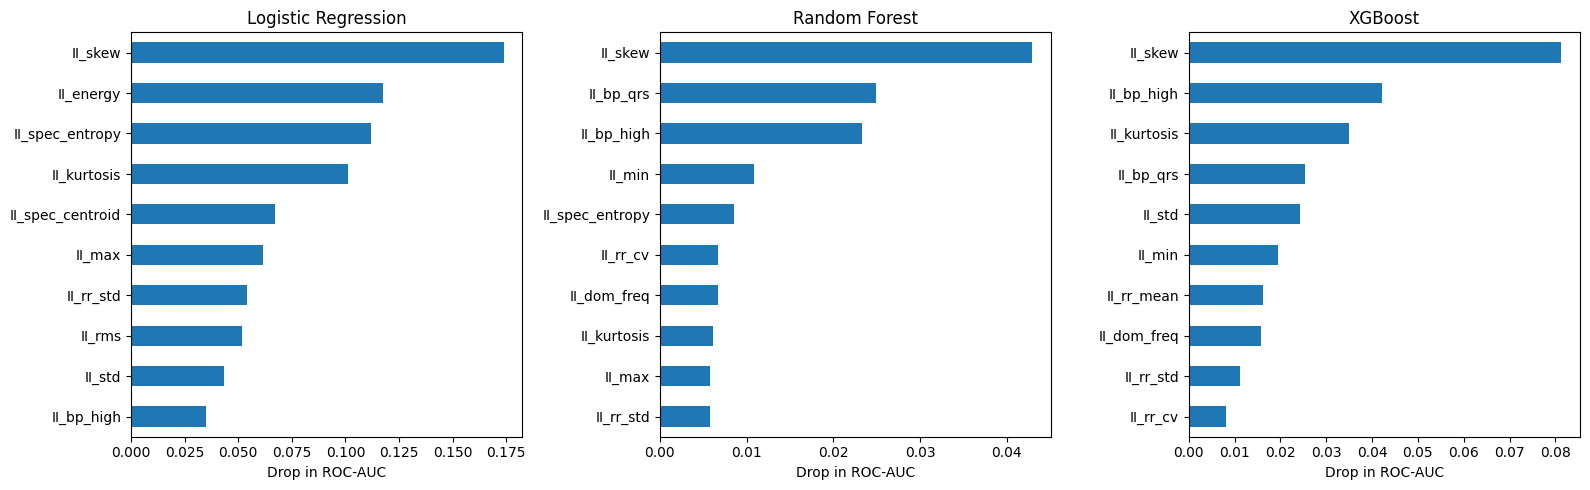

In [18]:
from sklearn.inspection import permutation_importance
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, (name, m) in zip(ax, fitted.items()):
    r = permutation_importance(m, X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=SEED)
    pd.Series(r.importances_mean, index=FEATURES).sort_values().tail(10).plot.barh(ax=a, title=name)
    a.set_xlabel("Drop in ROC-AUC")
plt.tight_layout(); plt.savefig(f"{WORK}/figures/permutation_importance.png", dpi=200); plt.show()

## 11. Save the model bundle + demo samples for the prototype

In [19]:
import joblib
bundle = {"model": fitted["XGBoost"], "features": FEATURES, "leads": LEADS, "dataset": "PTB-XL v1.0.3"}
joblib.dump(bundle, f"{WORK}/models/xgb_bundle.joblib")
for n, m in fitted.items():
    joblib.dump(m, f"{WORK}/models/{n.lower().replace(' ', '_')}.joblib")

# 3 normal + 3 abnormal HELD-OUT test records for the demo (features only + a label to display)
demo = pd.concat([te[te.abnormal == 0].head(3), te[te.abnormal == 1].head(3)])
demo_out = demo[FEATURES].copy(); demo_out["true_label"] = demo["abnormal"].map({0: "Normal", 1: "Abnormal"})
demo_out.to_csv(f"{WORK}/data/demo_samples.csv")

# self-test: reload from disk and predict
b = joblib.load(f"{WORK}/models/xgb_bundle.joblib")
pp = b["model"].predict_proba(demo[b["features"]])[:, 1]
assert ((pp >= 0) & (pp <= 1)).all()
print("Bundle reloads and predicts OK:", pp.round(2))

Bundle reloads and predicts OK: [0.25 0.27 0.23 0.88 0.29 0.15]


## 12. Streamlit prototype
Writes `app.py`. It accepts (a) a demo record, (b) a CSV of extracted features, or (c) a raw WFDB record (`.hea` + `.dat`),
then shows the predicted class, probability/confidence, the **not-a-diagnostic-tool** disclaimer and a SHAP explanation.

In [20]:
%%writefile app.py
"""Streamlit prototype: normal vs abnormal ECG (PTB-XL, extracted features, XGBoost + SHAP).
Run:  streamlit run app.py
"""
import os
import tempfile

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import shap
import streamlit as st

from ecg_features import extract_features

HERE = os.path.dirname(os.path.abspath(__file__))
st.set_page_config(page_title="ECG Normal vs Abnormal", layout="wide")


@st.cache_resource
def load_bundle():
    bundle = joblib.load(os.path.join(HERE, "models", "xgb_bundle.joblib"))
    return bundle, shap.TreeExplainer(bundle["model"])


def features_from_wfdb(files, leads):
    """Build one feature row from an uploaded WFDB record (.hea + .dat)."""
    import wfdb
    with tempfile.TemporaryDirectory() as tmp:
        for up in files:
            with open(os.path.join(tmp, up.name), "wb") as fh:
                fh.write(up.getbuffer())
        stems = [u.name[:-4] for u in files if u.name.endswith(".hea")]
        if not stems:
            raise ValueError("Please upload the .hea file together with the .dat file.")
        sig, fld = wfdb.rdsamp(os.path.join(tmp, stems[0]))
        return extract_features(sig, fld["sig_name"], fld["fs"], leads=leads, full_set_leads=("II",))


bundle, explainer = load_bundle()
FEATURES = bundle["features"]

st.title("ECG Normal vs Abnormal - research prototype")
st.warning(
    "**This is NOT a clinical diagnostic tool.** It is a student research prototype trained on the "
    "PTB-XL dataset and must never be used to make medical decisions."
)

mode = st.radio("Input type", ["Demo sample", "Upload feature CSV", "Upload WFDB record (.hea + .dat)"],
                horizontal=True)
X, truth = None, None
try:
    if mode == "Demo sample":
        demo = pd.read_csv(os.path.join(HERE, "data", "demo_samples.csv"), index_col="ecg_id")
        choice = st.selectbox("Held-out test record (ECG id)", demo.index)
        X = demo.loc[[choice], FEATURES]
        truth = demo.loc[choice, "true_label"] if "true_label" in demo.columns else None
    elif mode == "Upload feature CSV":
        up = st.file_uploader("CSV with the model's feature columns (first row is used)", type="csv")
        if up is not None:
            df = pd.read_csv(up)
            missing = [c for c in FEATURES if c not in df.columns]
            if missing:
                st.error(f"Missing {len(missing)} feature columns, e.g. {missing[:3]}")
            else:
                X = df[FEATURES].iloc[[0]]
    else:
        ups = st.file_uploader("Upload BOTH files of one record", accept_multiple_files=True)
        if ups and len(ups) >= 2:
            X = pd.DataFrame([features_from_wfdb(ups, bundle["leads"])])[FEATURES]
except Exception as exc:  # show a friendly message instead of a stack trace
    st.error(f"Could not read the input: {exc}")

if X is not None:
    prob = float(bundle["model"].predict_proba(X)[0, 1])
    label = "ABNORMAL" if prob >= 0.5 else "NORMAL"
    c1, c2, c3 = st.columns(3)
    c1.metric("Predicted class", label)
    c2.metric("Probability of abnormal", f"{prob:.1%}")
    c3.metric("Confidence in predicted class", f"{max(prob, 1 - prob):.1%}")
    st.progress(min(max(prob, 0.0), 1.0))
    if truth is not None:
        st.caption(f"Ground-truth label (demo only): {truth}")

    sv = explainer(X)
    st.subheader("Which features influenced this prediction?")
    st.caption("SHAP values are in log-odds: positive pushes towards ABNORMAL, negative towards NORMAL.")
    plt.figure()
    shap.plots.waterfall(sv[0], max_display=10, show=False)
    st.pyplot(plt.gcf(), bbox_inches="tight")
    top = pd.DataFrame({"feature": FEATURES, "value": X.iloc[0].values, "SHAP (log-odds)": sv.values[0]})
    top = top.reindex(top["SHAP (log-odds)"].abs().sort_values(ascending=False).index).head(8)
    st.dataframe(top.reset_index(drop=True), use_container_width=True)

Writing app.py


### requirements.txt and README.md (required by the brief)

In [21]:
import importlib.metadata as md
pkgs = ["wfdb", "numpy", "pandas", "scipy", "scikit-learn", "xgboost", "shap", "matplotlib", "seaborn", "joblib", "streamlit"]
lines = []
for p in pkgs:
    try: lines.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError: lines.append(p)        # streamlit is not preinstalled in Colab
open("requirements.txt", "w").write("\n".join(lines) + "\n")
print(open("requirements.txt").read())

wfdb==4.3.1
numpy==2.1.3
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
xgboost==3.4.1
shap==0.52.0
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0
streamlit



In [22]:
%%writefile README.md
# Normal vs Abnormal ECG classification (PTB-XL, explainable ML)

Binary classifier (normal vs abnormal ECG) using lead-II features extracted from PTB-XL v1.0.3,
three models (Logistic Regression, Random Forest, XGBoost), SHAP explanations and a Streamlit prototype.
**Not a clinical diagnostic tool.**

## Reproduce
1. Open `ptbxl_ecg_pipeline.ipynb` in Google Colab, run all cells (CPU runtime). It downloads PTB-XL, extracts features,
   trains/evaluates the models and saves `models/`, `figures/`, `data/`.
2. Run the prototype locally:
   ```
   python -m venv venv && source venv/bin/activate      # Windows: venv\Scripts\activate
   pip install -r requirements.txt
   streamlit run app.py
   ```
   Keep `app.py`, `ecg_features.py`, `models/` and `data/` in the same folder.

## Method summary
* Label: diagnostic superclass NORM only = normal, any other diagnostic superclass = abnormal.
* Split: official PTB-XL folds (1-8 train, 9 validation, 10 test); patients never cross folds (checked by assertion).
* Features: statistical, energy, Welch band-power, R-peak/HRV features from band-passed lead II (100 Hz).
* Models tuned on the validation fold; metrics on the test fold; SHAP + permutation importance.

Writing README.md


### Optional: run the Streamlit app from Colab
Colab has no browser tab for Streamlit, so we tunnel it. Open the printed `https://....loca.lt` link; if it asks for a password, use the IP printed first.
For the **recorded demo** it is smoother to download the project folder from Drive and run the app locally (see README).
Interrupt the last cell to stop the app.

In [23]:
!pip -q install streamlit
!curl -s https://ipv4.icanhazip.com
!nohup streamlit run app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &
!npx -y localtunnel --port 8501

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 102.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 124.7 MB/s eta 0:00:00
34.125.221.184
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹your url is: https://great-toys-type.loca.lt
34.125.221.184
^C


## 13. Final checklist
- [ ] `Runtime > Disconnect and delete runtime`, then **Run all** from a clean runtime (delete the cached feature CSV once to test the full path).
- [ ] Leakage assertions in section 4 pass; screenshot the printed message.
- [ ] Copy `figures/*.png` and the two CSV tables into the report.
- [ ] Test the app in a fresh local virtual environment using `requirements.txt`.
- [ ] Record the demo: one demo sample, one CSV upload, one WFDB upload, the disclaimer, the SHAP chart.